# Limited-overlap dictionary on SOCAL_H_76_230427_014845.x

The 8-motif dictionary in `SOCAL_H_76_230427_014845.x.limited_overlap` is kept, and further motifs are added on uncovered columns until coverage is at least 0.3. Added motifs use the same rules: `k` 1, widths 10 to 20, `tau` 0.9, and at least 10 placements. An empty pass does not stop the search.

The dictionary has 22 motifs. Coverage is 0.311 (5677 of 18270 columns). Placement counts run from 10 to 87, a ratio of 8.7. The atoms are rank 1.

Before specificity, each motif's dot-product sequence is shifted and scaled by a one-minute Gaussian mean and standard deviation. The number for a motif is the 90th percentile of the peak-to-baseline ratios of that sequence. A ratio is the shifted value at a local maximum divided by the same sequence after a shorter Gaussian smoothing, with standard deviation equal to half the motif width. Every finite ratio is included.

Output directory: `/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.limited_overlap_cov03`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows
from analysis.evaluation.core import _dot_products, _peak_ratios, _specificity_p90

OUT = Path("/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.limited_overlap_cov03")
GPL = Path("/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy")
summary = json.loads((OUT / "summary.json").read_text())
matchings = json.loads((OUT / "matchings.json").read_text())
counts = np.load(OUT / "counts.npz")
windows = discover_windows(GPL)
windows.sort(key=lambda window: (window.start_sample, window.window_id))
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)
knobs = summary["knobs"]
counts_kept = [row["n_placements"] for row in summary["motifs"]]
ratio = max(counts_kept) / min(counts_kept)
print(f"stop {summary['stop_reason']}")
print(
    f"coverage {summary['coverage']:.3f}  "
    f"({summary['n_bins_covered']} / {summary['n_bins_total']} columns)  "
    f"motifs {summary['n_motifs']}  placements {summary['n_placements']}  "
    f"max count {summary['max_count']}"
)
print(f"placement counts {min(counts_kept)} to {max(counts_kept)}  ratio {ratio:.3f}")
print("motif  placements  width")
for row in sorted(summary["motifs"], key=lambda item: item["motif_id"]):
    print(f"  {row['motif_id']:4d}  {row['n_placements']:6d}  {row['width']:4d}")
if "specificity" not in summary:
    spectrogram = np.concatenate([np.asarray(window.data, dtype=np.float64) for window in windows], axis=1)
    shift_sigma = 60.0 / sec_per_bin
    summary["specificity"] = []
    for row in summary["motifs"]:
        kernel = np.load(OUT / row["path"])
        if kernel.ndim == 3:
            kernel = kernel[0]
        ratios, percentile = _specificity_p90(
            _peak_ratios(_dot_products(spectrogram, kernel), float(row["width"] // 2), shift_sigma)
        )
        summary["specificity"].append(
            {
                "motif_id": row["motif_id"],
                "k": row["width"] // 2,
                "p90": None if not np.isfinite(percentile) else float(percentile),
                "n": int(ratios.size),
            }
        )
print("specificity  motif  k  p90  n")
for row in summary["specificity"]:
    print(f"  {row['motif_id']:4d}  {row['k']:3d}  {row['p90']:.4f}  {row['n']}")


stop coverage
coverage 0.311  (5677 / 18270 columns)  motifs 22  placements 444  max count 1
placement counts 10 to 87  ratio 8.700
motif  placements  width
     0      10    16
     2      34    11
     4      12    13
     6      27    11
    10      18    10
    13      11    14
    17      16    12
    19      14    10
    20      33    11
    84      20    10
    89      13    11
   103      14    13
   118      10    10
   130      11    14
   137      87    15
   154      26    12
   258      14    10
   313      10    13
   336      10    16
   350      14    10
   365      15    18
   380      25    17
specificity  motif  k  p90  n
     0    8  4.5850  2850
     2    5  2.1219  1837
     4    6  3.5201  2356
     6    5  2.2584  2499
    10    5  2.2732  2792
    13    7  4.2977  3130
    17    6  2.3901  1724
    19    5  2.7747  2475
    20    5  2.6462  1967
    84    5  2.6341  2108
    89    5  2.5306  2719
   103    6  2.8020  2403
   118    5  2.5979  2911
   130    7  

## Coverage by pass

Each point is the fraction of time columns covered by at least one kept placement after that pass.


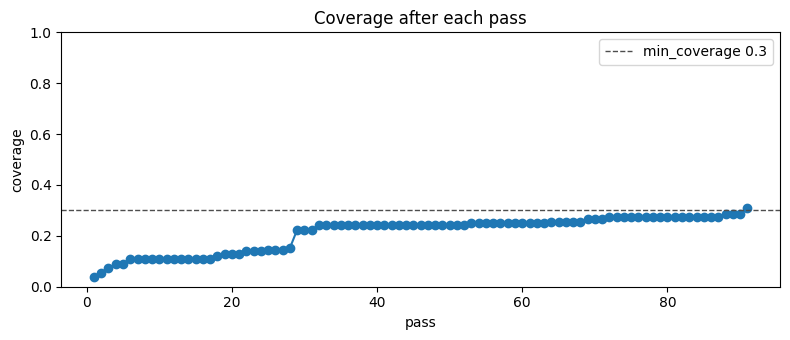

In [2]:
passes = summary["passes"]
outers = [row["outer"] for row in passes]
cover = []
last = 0.0
for row in passes:
    if "coverage" in row:
        last = row["coverage"]
    cover.append(last)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(outers, cover, marker="o", color="C0")
ax.axhline(knobs["min_coverage"], color="0.3", ls="--", lw=1, label=f"min_coverage {knobs['min_coverage']}")
ax.set_xlabel("pass")
ax.set_ylabel("coverage")
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Coverage after each pass")
fig.tight_layout()
plt.show()


## How many times each column is covered

The histogram counts time columns. The limit `k` is the darkest bar that can appear.

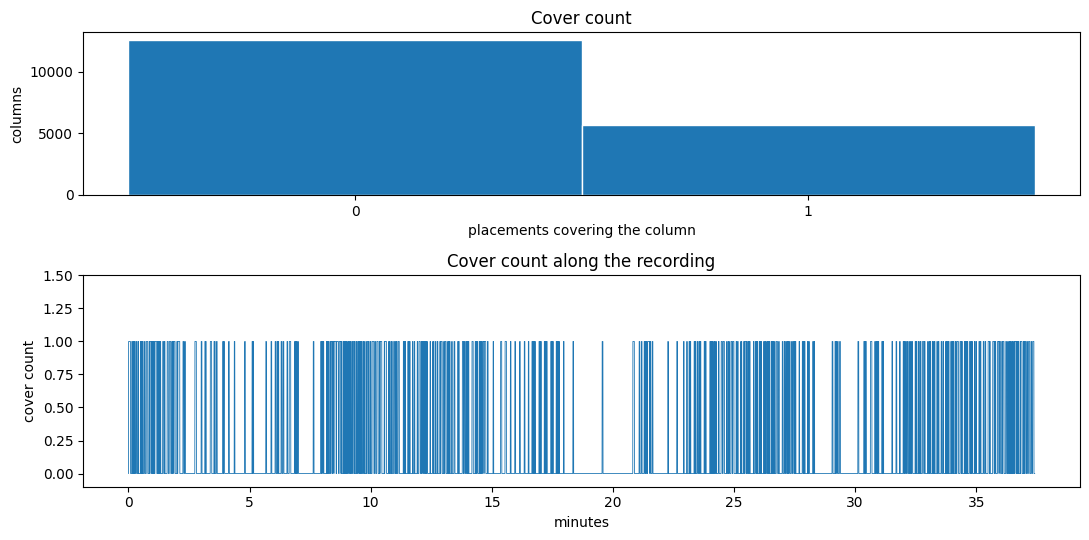

count 0: 12593 columns
count 1: 5677 columns


In [3]:
stacked = np.concatenate([counts[window.window_id] for window in windows])
minutes = np.arange(stacked.size) * sec_per_bin / 60.0
k = int(knobs["k"])
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), gridspec_kw={"height_ratios": [1, 1.3]})
bins = np.arange(-0.5, k + 1.5, 1)
axes[0].hist(stacked, bins=bins, color="C0", edgecolor="white")
axes[0].set_xticks(range(k + 1))
axes[0].set_xlabel("placements covering the column")
axes[0].set_ylabel("columns")
axes[0].set_title("Cover count")
axes[1].plot(minutes, stacked, color="C0", lw=0.6)
axes[1].set_xlabel("minutes")
axes[1].set_ylabel("cover count")
axes[1].set_ylim(-0.1, k + 0.5)
axes[1].set_title("Cover count along the recording")
fig.tight_layout()
plt.show()
for value in range(k + 1):
    print(f"count {value}: {int(np.sum(stacked == value))} columns")


## Placements per motif

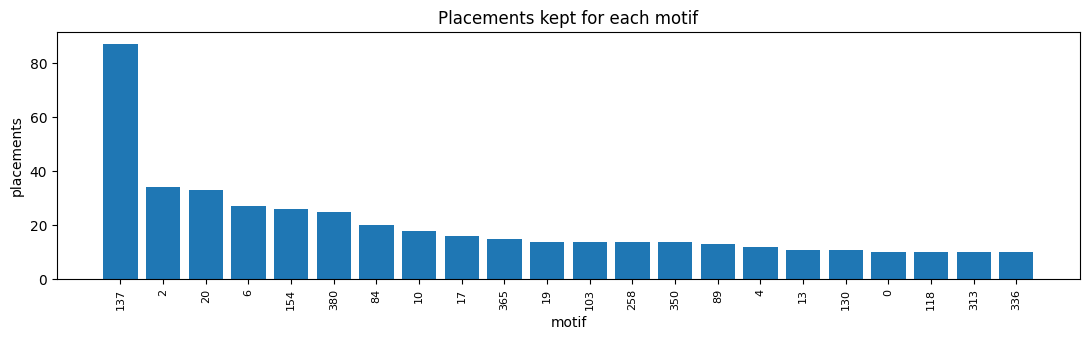

In [4]:
motifs = sorted(summary["motifs"], key=lambda row: -row["n_placements"])
names = [str(row["motif_id"]) for row in motifs]
heights = [row["n_placements"] for row in motifs]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(np.arange(len(names)), heights, color="C0")
ax.set_xticks(np.arange(len(names)), names, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("placements")
ax.set_title("Placements kept for each motif")
fig.tight_layout()
plt.show()


## Specificity

The dot-product sequence is shifted and scaled by a one-minute Gaussian before the peaks are measured. The number for a motif is the 90th percentile of its peak-to-baseline ratios on that sequence. A ratio is the shifted value at a local maximum divided by the same sequence after a shorter Gaussian smoothing, with standard deviation equal to half the motif width. Every finite ratio is included.


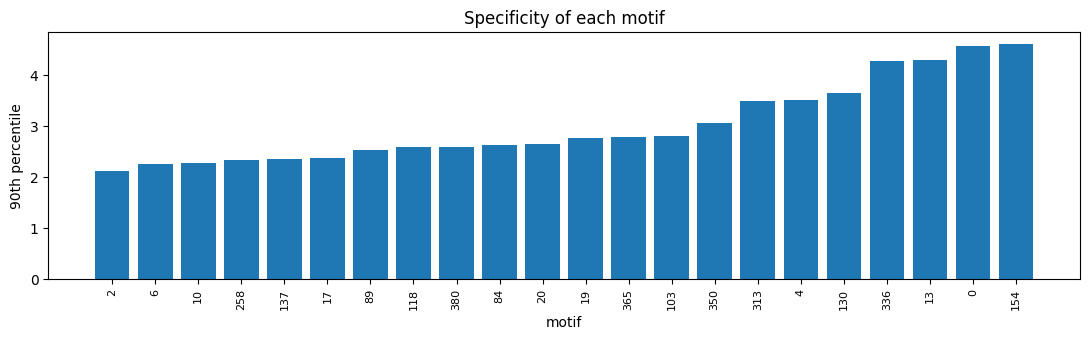

p90  min 2.122  max 4.613


In [5]:
spec = {row["motif_id"]: row for row in summary["specificity"]}
order = sorted(summary["motifs"], key=lambda row: spec[row["motif_id"]]["p90"])
labels = [str(row["motif_id"]) for row in order]
p90 = [spec[row["motif_id"]]["p90"] for row in order]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(np.arange(len(labels)), p90, color="C0")
ax.set_xticks(np.arange(len(labels)), labels, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("90th percentile")
ax.set_title("Specificity of each motif")
fig.tight_layout()
plt.show()
print(f"p90  min {min(p90):.3f}  max {max(p90):.3f}")


## Motifs

Each row of panels is one principal component of a motif, the cube root of its absolute value from about 12 Hz to 1500 Hz. The jet scale on each panel runs from that panel's 2nd percentile to its 98th. The title is the motif index, the component, and how many placements the motif kept.


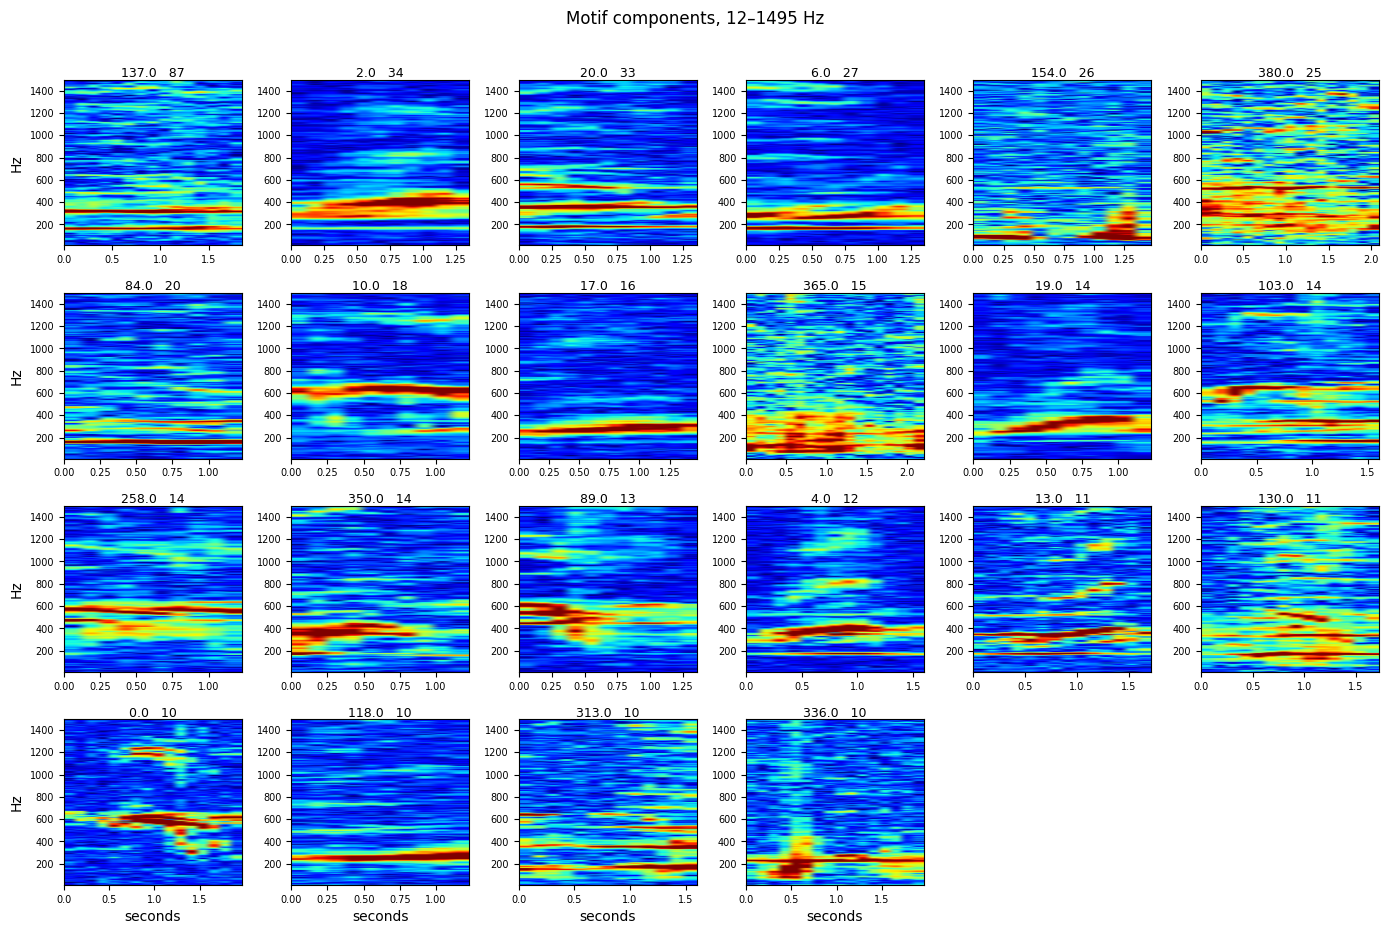

In [6]:
if not motifs:
    print("no motifs survived")
else:
    freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
    i0 = int(np.argmin(np.abs(freq_axis - float(windows[0].start_freq))))
    sample = np.load(OUT / motifs[0]["path"])
    n_freq = int(sample.shape[-2])
    freqs = freq_axis[i0 : i0 + n_freq]
    band = np.flatnonzero(freqs <= 1500.0)
    band_lo, band_hi = int(band[0]), int(band[-1]) + 1
    f_lo, f_hi = float(freqs[band_lo]), float(freqs[band_hi - 1])
    panels = []
    for row in motifs:
        atom = np.load(OUT / row["path"])
        components = atom if atom.ndim == 3 else atom[None, ...]
        for index, component in enumerate(components):
            panels.append((row, index, component))
    ncols = 6
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.3 * nrows))
    axes = np.atleast_2d(axes)
    for panel, (row, index, component) in enumerate(panels):
        r, c = divmod(panel, ncols)
        ax = axes[r, c]
        shown = display_from_spwhiten(component)[band_lo:band_hi]
        lo, hi = np.percentile(shown, [2, 98])
        if not np.isfinite(lo) or hi <= lo:
            lo, hi = float(np.min(shown)), float(np.max(shown))
        extent = [0.0, component.shape[1] * sec_per_bin, f_lo, f_hi]
        ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
        ax.set_title(f"{row['motif_id']}.{index}   {row['n_placements']}", fontsize=9, pad=2)
        ax.tick_params(labelsize=7)
        if c == 0:
            ax.set_ylabel("Hz")
        if r == nrows - 1:
            ax.set_xlabel("seconds")
    for panel in range(len(panels), nrows * ncols):
        r, c = divmod(panel, ncols)
        axes[r, c].axis("off")
    fig.suptitle(f"Motif components, {f_lo:.0f}–{f_hi:.0f} Hz", y=1.01)
    fig.tight_layout()
    plt.show()
